# Private-company SSM file

## What OneCredit uses this for

Most companies a OneCredit customer looks up are not listed. This notebook is the private-company check: the SSM profile and the SSM financial year, with identity numbers, dates of birth, street addresses, and person names left out of the frames.

- Revenue, the current ratio, liabilities / assets, and the loss rate are the size and solvency lines on a company that has no Bursa quote.
- An unsatisfied charge is a live secured claim. A shareholder with at least half the recorded shares is the control line.
- Z″ here uses profit before tax in place of EBIT, because interest expense is not on the payload. The score is the distress screen for that proxy.
- The extract is concentrated in construction activity codes, so the rates describe this book. A live check still scores the company in front of the analyst. Only a shared registration number can join a private row to a Bursa issuer.

Most of the companies a Malaysian counterparty wants to check are not on Bursa. This notebook uses the SSM-shaped extracts:

- `data/ssm_data/company_profiles.csv` — status, incorporation date, MSIC code, charges, officer counts, shareholder counts
- `data/ssm_data/company_financial_records.csv` — revenue, profit, assets, liabilities, audit flag

The profile payload also holds identity numbers, dates of birth, street addresses, and person names for officers and shareholders. `parse_ssm_profiles` drops those fields before a frame is built. The tables below are counts, amounts, states, and business codes.

Financial lines are in ringgit. Where the same company-year arrives from more than one vendor, the kept row is SSM_CBID, then CRIF_OMESTI, then RAFFTECH, then INFOMINA.

Profit before tax stands in for EBIT inside Z″. Interest expense is not on the payload, so this Z″ sits below the score that would use true EBIT whenever the company paid interest. `liability` is treated as total liabilities because assets minus that field line up with share capital plus retained earnings.


In [1]:
%matplotlib inline
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

NOTEBOOK_DIR = Path.cwd()
if not (NOTEBOOK_DIR / "credit_stats.py").exists():
    NOTEBOOK_DIR = Path.cwd() / "notebooks" / "credit_desk"
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

from credit_stats import (
    DATA_DIR,
    FIGURE_DIR,
    FINANCIAL_SECTOR_NAME,
    INSTITUTIONAL_INVESTOR_TYPES,
    LISTED_AMOUNT_UNIT,
    SSM_AMOUNT_UNIT,
    build_listed_panel,
    clean_state_name,
    age_in_years,
    cramers_v,
    distribution_row,
    epsilon_squared,
    herfindahl_from_positive_amounts,
    latest_rows,
    load_listed_statements,
    ownership_fraction,
    parse_ssm_financials,
    parse_ssm_profiles,
    peer_percentile,
    share_with_interval,
)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")


In [2]:
import math

profiles = parse_ssm_profiles()
financials = parse_ssm_financials()
latest_financials = latest_rows(financials, "registration_number", "fiscal_year")

profiles["company_age_years"] = age_in_years(profiles["incorporation_date"])

print(f"SSM profiles parsed: {len(profiles):,}")
print(f"Company-years after vendor collapse: {len(financials):,}")
print(f"Companies with a financial year: {latest_financials['registration_number'].nunique():,}")
print(f"Amount unit: {SSM_AMOUNT_UNIT}")
print(f"Financial years on the latest row: {int(latest_financials['fiscal_year'].min())}–{int(latest_financials['fiscal_year'].max())}")
print("Company status")
print(profiles["company_status"].value_counts(dropna=False).to_string())


SSM profiles parsed: 1,492
Company-years after vendor collapse: 4,099
Companies with a financial year: 1,440
Amount unit: RM
Financial years on the latest row: 2006–2024
Company status
company_status
Existing      1471
Dissolved       16
Winding up       5


In [3]:
ratio_names = [
    "current_ratio",
    "liabilities_to_assets",
    "net_profit_margin",
    "return_on_assets",
    "return_on_equity",
    "z_double_prime",
]
# Revenue is reported in ringgit. The log is used only for the skew of size.
positive_revenue = latest_financials["revenue"].where(latest_financials["revenue"] > 0)
latest_financials = latest_financials.copy()
latest_financials["log10_revenue"] = positive_revenue.map(math.log10)

distribution = pd.DataFrame(
    [distribution_row(latest_financials[ratio_name], ratio_name) for ratio_name in ratio_names]
    + [distribution_row(latest_financials["log10_revenue"], "log10_revenue")]
)

loss_share = share_with_interval(latest_financials["is_loss_making"])
distress_share = share_with_interval(latest_financials["distress_zone"].eq("distress"))
# Audit flag is a trial only when the payload carried Y or N.
audit_trials = latest_financials.loc[latest_financials["audit_flag_present"], "qualified_or_other_report"]
qualified_share = share_with_interval(audit_trials)

print(
    f"Loss-making on the latest year: {loss_share['share']:.1%} "
    f"(Wilson {loss_share['wilson_low']:.1%}–{loss_share['wilson_high']:.1%}, n = {loss_share['trials']})."
)
print(
    f"Z″ distress, using profit before tax as the EBIT proxy: {distress_share['share']:.1%} "
    f"(Wilson {distress_share['wilson_low']:.1%}–{distress_share['wilson_high']:.1%})."
)
print(
    f"Qualified or non-unqualified audit flag, where the flag is present: {qualified_share['share']:.1%} "
    f"(Wilson {qualified_share['wilson_low']:.1%}–{qualified_share['wilson_high']:.1%}, n = {qualified_share['trials']})."
)
distribution


Loss-making on the latest year: 33.1% (Wilson 30.7%–35.5%, n = 1440).
Z″ distress, using profit before tax as the EBIT proxy: 24.7% (Wilson 22.5%–26.9%).
Qualified or non-unqualified audit flag, where the flag is present: 1.3% (Wilson 0.8%–2.0%, n = 1341).


,ratio,n,median,mean,p25,p75,iqr,skew,excess_kurtosis,mad_outlier_share
0,current_ratio,1272,1.6252,7.6843,1.0281,3.1854,2.1573,15.8968,337.5049,0.1305
1,liabilities_to_assets,1415,0.5061,183.0863,0.2636,0.7603,0.4967,37.6162,"1,414.9879",0.0509
2,net_profit_margin,1264,0.0264,-3.9968,-0.0083,0.0752,0.0835,-33.0131,"1,126.9025",0.1938
3,return_on_assets,1415,0.0199,1.8616,-0.0163,0.0720,0.0884,32.7492,"1,218.9639",0.1004
4,return_on_equity,1206,0.0676,0.5190,-0.0071,0.1908,0.1979,33.3012,"1,137.4402",0.1310
5,z_double_prime,1267,3.5588,"-2,830.4914",0.5716,7.2005,6.6289,-35.5924,"1,266.8776",0.1144
6,log10_revenue,1264,6.8083,6.7077,6.1573,7.3262,1.1689,-0.5101,1.4818,0.0103


In [4]:
charge_share = share_with_interval(profiles["unsatisfied_charge_count"].gt(0))
# A missing share count is not a trial. Zero holders means the payload had no usable amounts.
known_largest = profiles["largest_shareholder_fraction"].dropna()
majority_owners = share_with_interval(known_largest.ge(0.50))
known_holder_count = profiles.loc[profiles["shareholder_count"].gt(0), "shareholder_count"]
sole_owner = share_with_interval(known_holder_count.eq(1))
charged = profiles.loc[profiles["unsatisfied_charge_count"].gt(0), "unsatisfied_charge_amount"]

control_distribution = pd.DataFrame(
    [
        distribution_row(profiles["director_count"], "director_count"),
        distribution_row(known_holder_count, "shareholder_count"),
        distribution_row(profiles["shareholder_hhi"], "shareholder_hhi"),
        distribution_row(known_largest, "largest_shareholder_fraction"),
        distribution_row(profiles["company_age_years"], "company_age_years"),
        distribution_row(charged, "unsatisfied_charge_amount_rm_if_charged"),
    ]
)
print(
    f"Companies with at least one unsatisfied charge: {charge_share['share']:.1%} "
    f"(Wilson {charge_share['wilson_low']:.1%}–{charge_share['wilson_high']:.1%}, n = {charge_share['trials']})."
)
print(
    f"Single recorded shareholder: {sole_owner['share']:.1%}. "
    f"Largest shareholder ≥ 50% of recorded shares: {majority_owners['share']:.1%} "
    f"(n = {majority_owners['trials']})."
)
print("Principal business codes")
print(
    profiles.loc[profiles["primary_business_name"].ne(""), "primary_business_name"]
    .value_counts()
    .head(12)
    .to_string()
)
control_distribution


Companies with at least one unsatisfied charge: 60.9% (Wilson 58.4%–63.4%, n = 1492).
Single recorded shareholder: 17.1%. Largest shareholder ≥ 50% of recorded shares: 78.5% (n = 1490).
Principal business codes
primary_business_name
CONSTRUCTION OF OTHER ENGINEERING PROJECTS N.E.C.                                                          287
CONSTRUCTION OF BUILDINGS N.E.C.                                                                           125
NON-RESIDENTIAL BUILDINGS                                                                                  112
ELECTRICAL WIRING AND FITTINGS                                                                              70
ACTIVITIES OF HOLDING COMPANIES                                                                             46
RETAIL SALE OF CONSTRUCTION MATERIALS, HARDWARE, PAINTS AND GLASS                                           44
WHOLESALE OF OTHER CONSTRUCTION MATERIALS, HARDWARE, PLUMBING AND HEATING EQUIPMENT AND SUPPLIES N.E.

,ratio,n,median,mean,p25,p75,iqr,skew,excess_kurtosis,mad_outlier_share
0,director_count,1492,2.0000,2.8412,2.0000,3.0000,1.0000,2.2731,8.2494,0.0174
1,shareholder_count,1490,2.0000,2.8812,2.0000,3.0000,1.0000,6.3294,58.6642,0.0322
2,shareholder_hhi,1490,0.5200,0.6023,0.3879,0.8751,0.4872,0.3360,-1.1401,0.0000
3,largest_shareholder_fraction,1490,0.6000,0.6651,0.5000,0.9331,0.4331,0.0865,-1.2534,0.0000
4,company_age_years,1492,32.5626,31.9531,29.3847,38.3751,8.9904,-0.4038,0.3355,0.0409
5,unsatisfied_charge_amount_rm_if_charged,909,"300,000.0000","36,568,791.0374",0.0000,"3,215,000.0000","3,215,000.0000",17.2703,352.5018,0.3124


In [5]:
listed_registration_numbers = set(
    pd.read_csv(DATA_DIR / "company_profile.csv", usecols=["registration_number"])["registration_number"]
    .astype(str)
    .str.strip()
)
ssm_registration_numbers = set(profiles["registration_number"])
financial_registration_numbers = set(latest_financials["registration_number"])
overlap_profiles = listed_registration_numbers & ssm_registration_numbers
overlap_financials = listed_registration_numbers & financial_registration_numbers
print(
    f"Listed registration numbers also present on the SSM profile extract: {len(overlap_profiles):,} "
    f"of {len(listed_registration_numbers):,} listed and {len(ssm_registration_numbers):,} SSM profiles."
)
print(f"Of those, with an SSM financial year: {len(overlap_financials):,}.")
print(
    "The private file and the Bursa file are mostly different populations. "
    "A limit process has to score them separately and only combine a company when the registration number matches."
)


Listed registration numbers also present on the SSM profile extract: 11 of 1,011 listed and 1,492 SSM profiles.
Of those, with an SSM financial year: 11.
The private file and the Bursa file are mostly different populations. A limit process has to score them separately and only combine a company when the registration number matches.


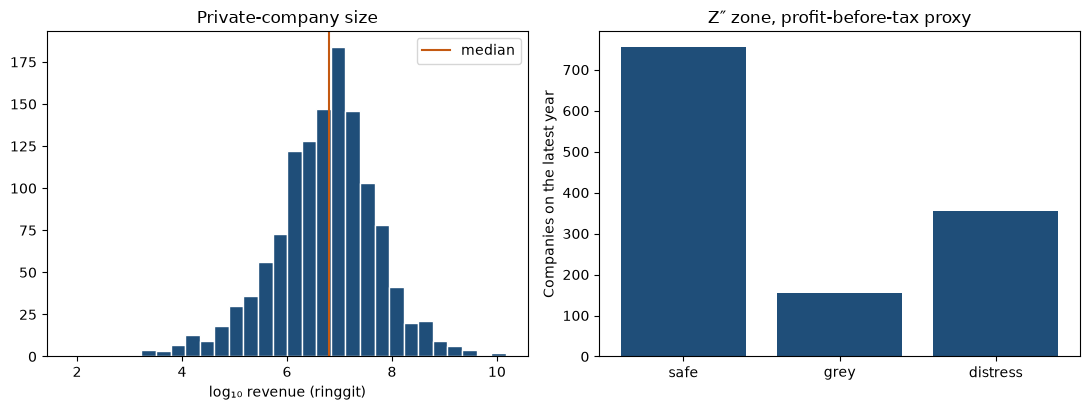

In [6]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4.2))
log_revenue = latest_financials["log10_revenue"].dropna()
axes[0].hist(log_revenue, bins=30, color="#1f4e79", edgecolor="white")
axes[0].axvline(log_revenue.median(), color="#c45911", linewidth=1.5, label="median")
axes[0].set_title("Private-company size")
axes[0].set_xlabel("log₁₀ revenue (ringgit)")
axes[0].legend()

zone_counts = latest_financials["distress_zone"].value_counts().reindex(["safe", "grey", "distress"])
axes[1].bar(zone_counts.index.astype(str), zone_counts.values, color="#1f4e79")
axes[1].set_title("Z″ zone, profit-before-tax proxy")
axes[1].set_ylabel("Companies on the latest year")
figure.tight_layout()
figure.savefig(FIGURE_DIR / "04_private_company_ssm_file.png", dpi=140)
plt.show()
